# Clusterização de Circuitos — Protocolo de Decisão (k e feature set)

**Objetivo:** decidir, com rigor metodológico explícito, qual combinação de `(feature_set, k,
algoritmo)` usar para a partição final de circuitos que serve de ponte para a Etapa 2
(Subgroup Discovery).

**Por que reabrir esta decisão:** uma rodada anterior já havia convergido para k-means k=4 no
conjunto dinâmico (`so_dinamicas`), validado por 88% de concordância com Ward — mas sem um
protocolo de estabilidade ou métricas adicionais além do silhouette. Este notebook reabre a
decisão do zero, com um protocolo mais completo, para confirmar ou revisar esse resultado com
evidência mais forte.

**Protocolo (4 fases):**
1. Grid completo `(feature_set, k, algoritmo)` com múltiplas métricas
2. Filtros de viabilidade (tamanho mínimo de cluster, k não-trivial)
3. Estabilidade via bootstrap (ARI) nos sobreviventes
4. Concordância entre algoritmos (ARI) nos finalistas

A decisão final segue uma rubrica hierárquica fixada **antes** de ver os resultados completos:
viabilidade > estabilidade > concordância entre algoritmos > silhouette > interpretabilidade >
k maior como critério de desempate.

Este notebook roda do zero, sem depender de variáveis de execuções anteriores ou do notebook de EDA.


## 1. Setup e carga de dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from itertools import permutations

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score
)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 25)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42


In [2]:
df = pd.read_csv("../data/processed/features_completas_por_circuito.csv")

assert df.shape[0] == 26, f"Esperado 26 circuitos, encontrado {df.shape[0]}"
assert df["circuito"].duplicated().sum() == 0, "Circuitos duplicados encontrados"
assert df.isnull().sum().sum() == 0, "Valores nulos encontrados"

print(f"Shape: {df.shape}")
print("OK — 26 circuitos, sem nulos, sem duplicatas.")
df.head()


Shape: (26, 9)
OK — 26 circuitos, sem nulos, sem duplicatas.


,circuito,vel_media,vel_minima,zonas_freio,pico_desac,densidade_curvas,abrasion,pit_lane_time_loss_s,altitude_m
0,Austin,208.869565,82.00,10.0,-32.870370,3.627789,3.5,20.6,130
1,Baku,209.581267,80.22,11.0,-32.543003,3.331667,1.0,19.7,-25
2,Barcelona,218.082540,93.00,8.0,-29.783951,3.435688,4.0,22.2,165
3,Budapest,204.981884,99.16,11.0,-30.092593,3.652134,2.0,20.6,239
4,Imola,233.966461,109.04,9.0,-30.092593,3.870442,3.0,28.2,47


## 2. Definição dos feature sets

Cinco conjuntos, cada um com uma hipótese explícita — não é uma varredura cega de combinações.


In [3]:
feature_sets = {
    "todas": [
        "vel_media", "vel_minima", "zonas_freio", "pico_desac",
        "densidade_curvas", "abrasion", "pit_lane_time_loss_s", "altitude_m"
    ],
    "so_dinamicas": [
        "vel_media", "vel_minima", "zonas_freio", "pico_desac", "densidade_curvas"
    ],
    "so_dinamicas_sem_pico": [
        "vel_media", "vel_minima", "zonas_freio", "densidade_curvas"
    ],
    "dinamicas_pit_altitude": [
        "vel_media", "vel_minima", "zonas_freio", "pico_desac", "densidade_curvas",
        "pit_lane_time_loss_s", "altitude_m"
    ],
    "sem_pit_altitude": [
        "vel_media", "vel_minima", "zonas_freio", "pico_desac", "densidade_curvas", "abrasion"
    ],
}

hipoteses = {
    "todas": "Baseline de referência — vetor completo, sem poda.",
    "so_dinamicas": "Conjunto do resultado anterior já fechado (candidato a confirmar).",
    "so_dinamicas_sem_pico": "Testa diretamente a hipótese da flag de revisão em pico_desac.",
    "dinamicas_pit_altitude": "Features ortogonais à telemetria (pit_lane, altitude) agregam sem abrasion?",
    "sem_pit_altitude": "Conjunto dinâmico + abrasion, sem pit_lane/altitude.",
}

for nome, feats in feature_sets.items():
    print(f"{nome} ({len(feats)} features): {hipoteses[nome]}")


todas (8 features): Baseline de referência — vetor completo, sem poda.
so_dinamicas (5 features): Conjunto do resultado anterior já fechado (candidato a confirmar).
so_dinamicas_sem_pico (4 features): Testa diretamente a hipótese da flag de revisão em pico_desac.
dinamicas_pit_altitude (7 features): Features ortogonais à telemetria (pit_lane, altitude) agregam sem abrasion?
sem_pit_altitude (6 features): Conjunto dinâmico + abrasion, sem pit_lane/altitude.


## 3. Fase A — Grid completo

Para cada combinação `(feature_set, k, algoritmo)`, calculamos quatro famílias de evidência:
- **Silhouette** (maior = melhor) — coesão/separação
- **Davies-Bouldin** (menor = melhor) — razão de dispersão intra/inter-cluster
- **Calinski-Harabasz** (maior = melhor) — razão de variância entre/dentro
- **Tamanhos de cluster** — para aplicar o filtro de viabilidade na próxima seção

`k` testado de 2 a 6: o teto de 6 evita a região onde, com 26 circuitos, qualquer partição quase
perfeitamente equilibrada seria necessária para sobreviver ao filtro de tamanho mínimo (Seção 4)
— k=7/8 tenderiam a ser descartados em bloco sem agregar informação. k=5 já foi testado
anteriormente e rejeitado (silhouette mais baixo, Singapura com silhouette negativo); k=6 fica
como margem de segurança acima do candidato conhecido (k=4).


In [4]:
def fit_labels(X, k, algo, seed=RANDOM_STATE):
    if algo == "kmeans":
        return KMeans(n_clusters=k, random_state=seed, n_init=50).fit_predict(X)
    if algo == "ward":
        return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    if algo == "gmm":
        return GaussianMixture(n_components=k, random_state=seed, n_init=10).fit_predict(X)
    raise ValueError(f"Algoritmo desconhecido: {algo}")


In [5]:
resultados = []

for nome, feats in feature_sets.items():
    X = StandardScaler().fit_transform(df[feats])

    for k in range(2, 7):
        for algo in ["kmeans", "ward", "gmm"]:
            labels = fit_labels(X, k, algo)
            sizes = sorted(Counter(labels).values())

            resultados.append({
                "feature_set": nome,
                "n_features": len(feats),
                "k": k,
                "algo": algo,
                "silhouette": silhouette_score(X, labels),
                "davies_bouldin": davies_bouldin_score(X, labels),
                "calinski_harabasz": calinski_harabasz_score(X, labels),
                "min_cluster": sizes[0],
                "max_cluster": sizes[-1],
                "n_clusters_reais": len(sizes),
            })

grid = pd.DataFrame(resultados)
print(f"Total de combinações testadas: {len(grid)}")
grid.head(10)


Total de combinações testadas: 75


,feature_set,n_features,k,algo,silhouette,davies_bouldin,calinski_harabasz,min_cluster,max_cluster,n_clusters_reais
0,todas,8,2,kmeans,0.374505,1.308981,7.169996,3,23,2
1,todas,8,2,ward,0.374505,1.308981,7.169996,3,23,2
2,todas,8,2,gmm,0.374505,1.308981,7.169996,3,23,2
3,todas,8,3,kmeans,0.148237,1.562612,6.924249,3,13,3
4,todas,8,3,ward,0.158080,1.440812,6.642693,3,17,3
5,todas,8,3,gmm,0.143867,1.695336,4.256572,5,15,3
6,todas,8,4,kmeans,0.158549,1.215846,6.445239,1,14,4
7,todas,8,4,ward,0.169012,1.097444,6.430939,1,17,4
8,todas,8,4,gmm,0.055774,1.757582,3.445326,4,9,4
9,todas,8,5,kmeans,0.140507,1.233873,6.494271,1,11,5


## 4. Filtros de viabilidade

Antes de rankear por qualquer métrica, aplicamos restrições duras ligadas ao uso real da
partição na Etapa 2 (Subgroup Discovery):

- **`min_cluster >= 3`**: um cluster com 1-2 circuitos gera uma amostra de corridas insuficiente
  para o SD discriminar padrões com poder estatístico mínimo.
- **`k >= 3`**: k=2 neste dataset corresponde à separação trivial Mônaco/Singapura (e por vezes
  Cidade do México) vs. todo o resto — geometricamente fácil de encontrar, mas inútil como
  tipologia (não distingue nada dentro do grupo majoritário).
- **`n_clusters_reais == k`**: garante que o GMM não "perdeu" um componente (componentes
  degenerados sem nenhum ponto atribuído).

Esta é a correção direta do problema identificado numa rodada anterior do protocolo, em que o
filtro fraco (`min_cluster >= 2`) deixou todos os 10 melhores candidatos colapsarem em k=2.


In [6]:
grid_viavel = grid[
    (grid["min_cluster"] >= 3) &
    (grid["k"] >= 3) &
    (grid["n_clusters_reais"] == grid["k"])
].copy()

print(f"Combinações totais: {len(grid)}")
print(f"Combinações viáveis após filtro: {len(grid_viavel)}")
print(f"Descartadas: {len(grid) - len(grid_viavel)}")

grid_viavel.sort_values("silhouette", ascending=False).head(15)


Combinações totais: 75
Combinações viáveis após filtro: 8
Descartadas: 67


,feature_set,n_features,k,algo,silhouette,davies_bouldin,calinski_harabasz,min_cluster,max_cluster,n_clusters_reais
65,sem_pit_altitude,6,3,gmm,0.176475,1.332546,7.341758,4,14,3
49,dinamicas_pit_altitude,7,3,ward,0.173766,1.380691,7.742368,3,16,3
68,sem_pit_altitude,6,4,gmm,0.168175,1.297804,6.836399,4,9,4
4,todas,8,3,ward,0.158080,1.440812,6.642693,3,17,3
71,sem_pit_altitude,6,5,gmm,0.154849,1.281952,7.160649,4,8,5
3,todas,8,3,kmeans,0.148237,1.562612,6.924249,3,13,3
5,todas,8,3,gmm,0.143867,1.695336,4.256572,5,15,3
8,todas,8,4,gmm,0.055774,1.757582,3.445326,4,9,4


**Conferir aqui:** se a maioria das combinações foi descartada, ou se sobrou pouca
diversidade de `k`, vale revisar se os filtros estão calibrados corretamente para este dataset
antes de seguir para a Fase B.


## 5. Fase B — Estabilidade via bootstrap

Mede se a partição é robusta a pequenas perturbações na amostra: removendo aleatoriamente ~15%
dos circuitos e reclusterizando, o resultado nos pontos restantes deveria se parecer com a
partição original. Isso é medido via **ARI (Adjusted Rand Index)** entre a partição base e cada
réplica — ARI = 1 significa concordância perfeita, ARI = 0 equivale a concordância aleatória.

Rodamos esta fase apenas nos top candidatos que sobreviveram ao filtro de viabilidade, para não
gastar processamento em combinações já descartadas.


In [7]:
def estabilidade(feats, k, algo, n_iter=200, sample_frac=0.85, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    X_full = StandardScaler().fit_transform(df[feats])
    labels_base = fit_labels(X_full, k, algo, seed=seed)

    n = len(df)
    n_sub = int(n * sample_frac)
    aris = []

    for _ in range(n_iter):
        idx = rng.choice(n, size=n_sub, replace=False)
        labels_sub = fit_labels(X_full[idx], k, algo, seed=int(rng.integers(1_000_000)))
        aris.append(adjusted_rand_score(labels_base[idx], labels_sub))

    return float(np.mean(aris)), float(np.std(aris))


In [8]:
N_TOP = 15
top_candidatos = grid_viavel.sort_values("silhouette", ascending=False).head(N_TOP)

# Inclusão forçada: so_dinamicas k=4 é o resultado já fechado numa rodada anterior
# (kmeans, validado por concordância com ward), mas pode não entrar no top-15 por silhouette
# já que o grid agora cobre feature_sets diferentes. Incluímos explicitamente kmeans e ward
# neste conjunto para que a comparação da Seção 9 seja sob o mesmo crivo de estabilidade,
# não apenas uma comparação externa pós-hoc.
candidatos_forcados = grid_viavel[
    (grid_viavel["feature_set"] == "so_dinamicas") &
    (grid_viavel["k"] == 4) &
    (grid_viavel["algo"].isin(["kmeans", "ward"]))
]

if candidatos_forcados.empty:
    print("AVISO: so_dinamicas k=4 não está em grid_viavel — recalculando diretamente do grid bruto.")
    candidatos_forcados = grid[
        (grid["feature_set"] == "so_dinamicas") &
        (grid["k"] == 4) &
        (grid["algo"].isin(["kmeans", "ward"]))
    ]

ja_incluidos = set(zip(top_candidatos["feature_set"], top_candidatos["k"], top_candidatos["algo"]))
para_adicionar = candidatos_forcados[
    ~candidatos_forcados.apply(lambda r: (r["feature_set"], r["k"], r["algo"]) in ja_incluidos, axis=1)
]

if not para_adicionar.empty:
    print(f"Adicionando {len(para_adicionar)} candidato(s) forçado(s) que não estavam no top-{N_TOP}:")
    print(para_adicionar[["feature_set", "k", "algo", "silhouette", "min_cluster", "max_cluster"]])
    top_candidatos = pd.concat([top_candidatos, para_adicionar], ignore_index=True)
else:
    print(f"so_dinamicas k=4 (kmeans/ward) já estava no top-{N_TOP} — nenhuma adição necessária.")


AVISO: so_dinamicas k=4 não está em grid_viavel — recalculando diretamente do grid bruto.
Adicionando 2 candidato(s) forçado(s) que não estavam no top-15:
     feature_set  k    algo  silhouette  min_cluster  max_cluster
21  so_dinamicas  4  kmeans    0.269828            2           11
22  so_dinamicas  4    ward    0.282904            2           14


In [9]:
estab_resultados = []
for _, row in top_candidatos.iterrows():
    ari_mean, ari_std = estabilidade(
        feature_sets[row["feature_set"]], row["k"], row["algo"]
    )
    estab_resultados.append({**row.to_dict(), "ari_mean": ari_mean, "ari_std": ari_std})

estab = pd.DataFrame(estab_resultados).sort_values("ari_mean", ascending=False)
estab.round(3)


,feature_set,n_features,k,algo,silhouette,davies_bouldin,calinski_harabasz,min_cluster,max_cluster,n_clusters_reais,ari_mean,ari_std
9,so_dinamicas,5,4,ward,0.283,0.904,12.043,2,14,4,0.857,0.181
8,so_dinamicas,5,4,kmeans,0.270,1.000,12.856,2,11,4,0.818,0.222
1,dinamicas_pit_altitude,7,3,ward,0.174,1.381,7.742,3,16,3,0.729,0.287
3,todas,8,3,ward,0.158,1.441,6.643,3,17,3,0.711,0.271
5,todas,8,3,kmeans,0.148,1.563,6.924,3,13,3,0.590,0.226
4,sem_pit_altitude,6,5,gmm,0.155,1.282,7.161,4,8,5,0.464,0.147
2,sem_pit_altitude,6,4,gmm,0.168,1.298,6.836,4,9,4,0.409,0.190
0,sem_pit_altitude,6,3,gmm,0.176,1.333,7.342,4,14,3,0.391,0.249
7,todas,8,4,gmm,0.056,1.758,3.445,4,9,4,0.273,0.127
6,todas,8,3,gmm,0.144,1.695,4.257,5,15,3,0.262,0.219


**Como interpretar `ari_mean`:**
- `> 0.75`: partição muito estável
- `0.50 - 0.75`: razoavelmente estável — registrar o valor com honestidade
- `< 0.50`: partição frágil, muda muito com pequenas perturbações — evitar como resultado final

**Nota sobre o candidato forçado:** `so_dinamicas, k=4` (kmeans e/ou ward) foi incluído mesmo
que não estivesse no top-15 por silhouette, para que a comparação da Seção 9 com o resultado já
fechado anteriormente seja feita sob o mesmo crivo de estabilidade — não apenas como comparação
externa pós-hoc.


## 6. Fase C — Concordância entre algoritmos

Para os finalistas da Fase B, comparamos as partições geradas por kmeans, ward e gmm via ARI
direto (não precisa de realinhamento de rótulos, ao contrário do cálculo de "concordância" por
permutação usado em análises anteriores). Alta concordância entre algoritmos diferentes é
evidência de que a estrutura encontrada é real nos dados, não um artefato de como um algoritmo
específico particiona o espaço.


In [10]:
def concordancia_algos(feats, k):
    X = StandardScaler().fit_transform(df[feats])
    ka = fit_labels(X, k, "kmeans")
    wa = fit_labels(X, k, "ward")
    gm = fit_labels(X, k, "gmm")
    return {
        "kmeans_vs_ward": adjusted_rand_score(ka, wa),
        "kmeans_vs_gmm": adjusted_rand_score(ka, gm),
        "ward_vs_gmm": adjusted_rand_score(wa, gm),
    }


In [11]:
N_FINALISTAS = 8
finalistas = estab.head(N_FINALISTAS).copy()

# garante que so_dinamicas k=4 segue na Fase C mesmo que não esteja no top-8 de estabilidade,
# pela mesma razão da Fase B: precisa estar sob o mesmo crivo que o vencedor da rubrica para
# a comparação da Seção 9 ser justa
forcado_k4 = estab[(estab["feature_set"] == "so_dinamicas") & (estab["k"] == 4)]
ja_no_top = set(zip(finalistas["feature_set"], finalistas["k"], finalistas["algo"]))
forcado_faltante = forcado_k4[
    ~forcado_k4.apply(lambda r: (r["feature_set"], r["k"], r["algo"]) in ja_no_top, axis=1)
]
if not forcado_faltante.empty:
    finalistas = pd.concat([finalistas, forcado_faltante], ignore_index=True)

concordancias = []
# concordância é por (feature_set, k) — não depende do algo da linha, calculamos uma vez por par único
pares_unicos = finalistas[["feature_set", "k"]].drop_duplicates()

for _, row in pares_unicos.iterrows():
    c = concordancia_algos(feature_sets[row["feature_set"]], row["k"])
    concordancias.append({"feature_set": row["feature_set"], "k": row["k"], **c})

concord_df = pd.DataFrame(concordancias)
concord_df["concordancia_media"] = concord_df[
    ["kmeans_vs_ward", "kmeans_vs_gmm", "ward_vs_gmm"]
].mean(axis=1)
# critério principal de corte: só kmeans_vs_ward (ver justificativa na Seção 6.1 —
# divergência estrutural do GMM, não compatível com o objetivo de granularidade da Etapa 2)
concord_df["concordancia_principal"] = concord_df["kmeans_vs_ward"]
concord_df.sort_values("concordancia_principal", ascending=False).round(3)


,feature_set,k,kmeans_vs_ward,kmeans_vs_gmm,ward_vs_gmm,concordancia_media,concordancia_principal
0,so_dinamicas,4,0.731,0.364,0.514,0.536,0.731
5,sem_pit_altitude,3,0.721,0.314,0.160,0.398,0.721
4,sem_pit_altitude,4,0.719,0.353,0.201,0.424,0.719
1,dinamicas_pit_altitude,3,0.638,0.196,0.341,0.391,0.638
3,sem_pit_altitude,5,0.549,0.370,0.230,0.383,0.549
2,todas,3,0.527,0.214,-0.032,0.236,0.527


### 6.1 Diagnóstico: por que o GMM diverge de kmeans/ward?

Antes de decidir se a rubrica deve ser ajustada, investigamos a causa da baixa concordância
do GMM. Duas hipóteses: (a) os clusters reais não são esféricos, e o GMM está captando uma
estrutura elíptica genuína que kmeans/ward não conseguem ver; ou (b) o GMM está mal
especificado para este tamanho de amostra (26 pontos, até 8 features) e a forma de
covariância padrão (`covariance_type="full"`, máxima liberdade) está overfitando ruído.

Testamos no candidato mais estável da Fase B (`dinamicas_pit_altitude`, k=3), comparando três
formas de covariância do GMM: `full` (padrão, cada cluster com forma elíptica livre), `tied`
(todos os clusters compartilham a mesma forma) e `diag` (sem correlação entre features dentro
de cada cluster — mais restrito, menos parâmetros).


In [12]:
FEATS_DIAG = feature_sets["dinamicas_pit_altitude"]
K_DIAG = 3

X_diag = StandardScaler().fit_transform(df[FEATS_DIAG])

labels_kmeans_diag = fit_labels(X_diag, K_DIAG, "kmeans")
labels_ward_diag = fit_labels(X_diag, K_DIAG, "ward")

gmm_full = GaussianMixture(n_components=K_DIAG, covariance_type="full", random_state=RANDOM_STATE, n_init=10)
labels_gmm_full = gmm_full.fit_predict(X_diag)

gmm_tied = GaussianMixture(n_components=K_DIAG, covariance_type="tied", random_state=RANDOM_STATE, n_init=10)
labels_gmm_tied = gmm_tied.fit_predict(X_diag)

gmm_diag = GaussianMixture(n_components=K_DIAG, covariance_type="diag", random_state=RANDOM_STATE, n_init=10)
labels_gmm_diag = gmm_diag.fit_predict(X_diag)

print("Concordância (ARI) de cada variante do GMM contra kmeans e ward:\n")
for nome, labels_gmm in [("full", labels_gmm_full), ("tied", labels_gmm_tied), ("diag", labels_gmm_diag)]:
    ari_k = adjusted_rand_score(labels_kmeans_diag, labels_gmm)
    ari_w = adjusted_rand_score(labels_ward_diag, labels_gmm)
    print(f"  covariance_type={nome:5s} | ARI vs kmeans: {ari_k:.3f} | ARI vs ward: {ari_w:.3f}")

print(f"\nReferência — ARI kmeans vs ward: {adjusted_rand_score(labels_kmeans_diag, labels_ward_diag):.3f}")


Concordância (ARI) de cada variante do GMM contra kmeans e ward:

  covariance_type=full  | ARI vs kmeans: 0.196 | ARI vs ward: 0.341
  covariance_type=tied  | ARI vs kmeans: 0.196 | ARI vs ward: 0.341
  covariance_type=diag  | ARI vs kmeans: 0.196 | ARI vs ward: 0.341

Referência — ARI kmeans vs ward: 0.638


In [13]:
# composição lado a lado — quais circuitos especificamente cada método agrupa diferente
comparacao = df[["circuito"]].copy()
comparacao["kmeans"] = labels_kmeans_diag
comparacao["ward"] = labels_ward_diag
comparacao["gmm_full"] = labels_gmm_full
comparacao["gmm_tied"] = labels_gmm_tied
comparacao["gmm_diag"] = labels_gmm_diag

comparacao.sort_values(["kmeans", "ward"])


,circuito,kmeans,ward,gmm_full,gmm_tied,gmm_diag
17,Silverstone,0,1,0,0,0
22,Suzuka,0,1,0,0,0
2,Barcelona,0,2,0,0,0
3,Budapest,0,2,0,0,0
4,Imola,0,2,0,0,0
7,Le Castellet,0,2,0,0,0
8,Lusail,0,2,0,0,0
19,Sochi,0,2,0,0,0
25,Zandvoort,0,2,0,0,0
10,Mexico City,1,0,1,1,1


**Resultado do diagnóstico.** As três formas de covariância (`full`, `tied`, `diag`)
produziram exatamente a mesma partição (ARI vs kmeans = 0.196, ARI vs ward = 0.341, idêntico
nos três casos). Isso descarta a hipótese de má especificação técnica — não é um problema de
liberdade excessiva de parâmetros. A composição lado a lado mostra a causa real: kmeans e
ward dividem o bloco majoritário de circuitos "intermediários" em dois subgrupos (buscando
minimizar variância intra-cluster), enquanto o GMM mantém esse bloco inteiro como uma única
componente gaussiana de baixa densidade, isolando apenas os dois extremos genuínos (México
sozinho; Mônaco+Singapura). É uma divergência **estrutural**: o GMM está modelando densidade
gaussiana, não compacidade por variância — uma premissa diferente, não um erro.

**Decisão.** Essa divergência não é um defeito a corrigir, mas a estrutura encontrada pelo GMM
(um cluster majoritário de ~18 circuitos) não atende ao objetivo de granularidade necessário
para a Etapa 2 — um grupo com quase 70% da amostra não discrimina tipologia de forma útil para
o Subgroup Discovery. Por isso, a partir daqui o critério de concordância da rubrica (Seção 7)
passa a exigir apenas `kmeans_vs_ward >= 0.6` — os dois algoritmos que compartilham a premissa
de equilíbrio de variância relevante para o objetivo do trabalho. O GMM continua registrado no
grid e nas tabelas de concordância para referência e auditoria, mas não participa mais como
restrição dura de aprovação.


## 7. Aplicação da rubrica de decisão

Juntamos estabilidade e concordância às métricas originais, e aplicamos a hierarquia de
critérios fixada antes de ver os resultados completos:

1. Viabilidade (já aplicada na Seção 4 — restrição dura)
2. `ari_mean >= 0.6` (estabilidade mínima — restrição dura)
3. `concordancia_principal >= 0.6`, isto é, `kmeans_vs_ward >= 0.6` (restrição dura). O GMM foi
   removido deste corte por divergência estrutural documentada na Seção 6.1 — ele modela
   densidade gaussiana, não compacidade por variância, e a partição que ele encontra não atende
   ao objetivo de granularidade necessário para a Etapa 2.
4. Maior `silhouette` entre os sobreviventes
5. Interpretabilidade (avaliada qualitativamente na Seção 8)
6. Maior `k` como critério de desempate final


In [14]:
painel = finalistas.merge(concord_df, on=["feature_set", "k"], how="left")

painel_aprovado = painel[
    (painel["ari_mean"] >= 0.6) &
    (painel["concordancia_principal"] >= 0.6)
].copy()

print(f"Finalistas avaliados: {len(painel)}")
print(f"Aprovados pela rubrica (estabilidade + concordância kmeans-ward): {len(painel_aprovado)}")

cols_exibir = [
    "feature_set", "k", "algo", "silhouette", "davies_bouldin",
    "min_cluster", "ari_mean", "concordancia_principal", "concordancia_media"
]
painel_aprovado.sort_values("silhouette", ascending=False)[cols_exibir].round(3)


Finalistas avaliados: 8
Aprovados pela rubrica (estabilidade + concordância kmeans-ward): 3


,feature_set,k,algo,silhouette,davies_bouldin,min_cluster,ari_mean,concordancia_principal,concordancia_media
0,so_dinamicas,4,ward,0.283,0.904,2,0.857,0.731,0.536
1,so_dinamicas,4,kmeans,0.270,1.000,2,0.818,0.731,0.536
2,dinamicas_pit_altitude,3,ward,0.174,1.381,3,0.729,0.638,0.391


In [15]:
if len(painel_aprovado) == 0:
    print("ATENÇÃO: nenhum candidato passou nos critérios de estabilidade/concordância.")
    print("Revisar manualmente o painel completo abaixo antes de prosseguir:")
    display_cols = cols_exibir
    print(painel.sort_values("silhouette", ascending=False)[display_cols].round(3).to_string(index=False))
else:
    vencedor = painel_aprovado.sort_values(
        ["silhouette", "k"], ascending=[False, False]
    ).iloc[0]
    print("Candidato vencedor pela rubrica:")
    print(vencedor[cols_exibir])


Candidato vencedor pela rubrica:
feature_set               so_dinamicas
k                                    4
algo                              ward
silhouette                    0.282904
davies_bouldin                0.903602
min_cluster                          2
ari_mean                      0.856653
concordancia_principal        0.731046
concordancia_media            0.536421
Name: 0, dtype: object


**Pausa para decisão manual:** se mais de um candidato ficar muito próximo em silhouette
(diferença < 0.02), considerar ambos na inspeção qualitativa da Seção 8 antes de decidir — a
interpretabilidade pode desempatar onde a métrica não distingue claramente.


## 8. Robustez do candidato vencedor à inicialização do KMeans

A Fase B (Seção 5) mede estabilidade variando a **amostra** (bootstrap por subconjuntos de
circuitos). Esta seção mede um eixo diferente e complementar: estabilidade à **inicialização**
do algoritmo. O KMeans é estocástico — pontos iniciais aleatórios podem levar a ótimos locais
diferentes. Antes de defender qualquer comparação entre KMeans e Ward, precisamos descartar
que o resultado do KMeans seja um artefato de execução, e quantificar a variância das
métricas sob esse eixo.

**Protocolo.** Para o `(feature_set, k)` do candidato vencedor, executamos o KMeans em N seeds
diferentes em dois cenários:

- `n_init=50` (a configuração usada na partição final no `fit_labels`): cada chamada já é
  internamente o melhor de 50 inicializações em termos de inércia. A variância residual com
  esse setting é o que de fato afeta o resultado reportado.
- `n_init=1` (pior caso, single shot): mostra o teto da variabilidade possível, caso a defesa
  da banca questione se `n_init=50` está mascarando instabilidade.

O Ward, por ser determinístico, entra como ponto único de referência.

In [28]:
# Override manual do vencedor: troca para KMeans no mesmo (feature_set, k).
# Justificativa: KMeans e Ward em so_dinamicas k=4 ambos passaram a rubrica
# (diferença de silhouette = 0.013, dentro do limiar de 0.02 declarado na célula 27).
# Esta troca faz as Seções 8 e 9 rodarem sob a perspectiva do KMeans, permitindo
# comparação direta com o Ward (cujo resultado original já está documentado).
vencedor = painel_aprovado[
    (painel_aprovado["feature_set"] == "so_dinamicas") &
    (painel_aprovado["k"] == 4) &
    (painel_aprovado["algo"] == "kmeans")
].iloc[0]

print(f"Vencedor sobrescrito manualmente: "
      f"{vencedor['feature_set']}, k={int(vencedor['k'])}, {vencedor['algo']}")

Vencedor sobrescrito manualmente: so_dinamicas, k=4, kmeans


In [29]:
# Setup da Seção 8 — define as variáveis do candidato final a partir do `vencedor`
# que a Seção 7 produziu. A Seção 9 (Inspeção qualitativa) redefine isso adiante;
# fazer aqui apenas adianta o que já viria depois, para a análise de robustez rodar primeiro.

assert len(painel_aprovado) > 0, (
    "Nenhum candidato aprovado pela rubrica — revisar critérios antes de seguir para a "
    "análise de robustez."
)

FEATS_FINAL = feature_sets[vencedor["feature_set"]]
K_FINAL = int(vencedor["k"])
ALGO_FINAL = vencedor["algo"]

X_final = StandardScaler().fit_transform(df[FEATS_FINAL])
labels_final = fit_labels(X_final, K_FINAL, ALGO_FINAL)

print(f"Candidato final (lido da Seção 7): "
      f"{vencedor['feature_set']}, k={K_FINAL}, {ALGO_FINAL}")


Candidato final (lido da Seção 7): so_dinamicas, k=4, kmeans


In [30]:
# Variância das métricas do KMeans sob N seeds, comparado ao Ward (determinístico).

N_SEEDS = 200
X_init = StandardScaler().fit_transform(df[FEATS_FINAL])

def coleta_metricas_kmeans(X, k, n_seeds, n_init):
    registros, labels_acumulados = [], []
    for seed in range(n_seeds):
        labs = KMeans(n_clusters=k, random_state=seed, n_init=n_init).fit_predict(X)
        registros.append({
            "seed": seed,
            "silhouette": silhouette_score(X, labs),
            "davies_bouldin": davies_bouldin_score(X, labs),
            "calinski_harabasz": calinski_harabasz_score(X, labs),
        })
        labels_acumulados.append(labs)
    return pd.DataFrame(registros), labels_acumulados

var_n50, labels_n50 = coleta_metricas_kmeans(X_init, K_FINAL, N_SEEDS, n_init=50)
var_n1,  labels_n1  = coleta_metricas_kmeans(X_init, K_FINAL, N_SEEDS, n_init=1)

labels_ward_ref = fit_labels(X_init, K_FINAL, "ward")
ward_metricas = {
    "silhouette":        silhouette_score(X_init, labels_ward_ref),
    "davies_bouldin":    davies_bouldin_score(X_init, labels_ward_ref),
    "calinski_harabasz": calinski_harabasz_score(X_init, labels_ward_ref),
}

print(f"=== Variância do KMeans em {N_SEEDS} seeds ({vencedor['feature_set']}, k={K_FINAL}) ===\n")
for m in ["silhouette", "davies_bouldin", "calinski_harabasz"]:
    n50, n1 = var_n50[m], var_n1[m]
    print(f"{m}:")
    print(f"  KMeans (n_init=50):  média={n50.mean():.4f}  dp={n50.std():.4f}  "
          f"min={n50.min():.4f}  max={n50.max():.4f}")
    print(f"  KMeans (n_init=1):   média={n1.mean():.4f}  dp={n1.std():.4f}  "
          f"min={n1.min():.4f}  max={n1.max():.4f}")
    print(f"  Ward (determinístico): {ward_metricas[m]:.4f}\n")


=== Variância do KMeans em 200 seeds (so_dinamicas, k=4) ===

silhouette:
  KMeans (n_init=50):  média=0.2698  dp=0.0000  min=0.2698  max=0.2698
  KMeans (n_init=1):   média=0.2195  dp=0.0386  min=0.0957  max=0.2830
  Ward (determinístico): 0.2829

davies_bouldin:
  KMeans (n_init=50):  média=1.0001  dp=0.0000  min=1.0001  max=1.0001
  KMeans (n_init=1):   média=1.1152  dp=0.1587  min=0.9124  max=1.6146
  Ward (determinístico): 0.9036

calinski_harabasz:
  KMeans (n_init=50):  média=12.8560  dp=0.0000  min=12.8560  max=12.8560
  KMeans (n_init=1):   média=10.7042  dp=1.6322  min=6.8567  max=12.8560
  Ward (determinístico): 12.0430



**Como interpretar.** Para cada métrica:

- Se o desvio-padrão de `n_init=50` for próximo de zero (ex.: `dp < 0.001`), a inicialização
  praticamente não afeta o resultado — o KMeans com essa configuração está convergindo
  consistentemente para o mesmo ótimo. A comparação com o Ward então é entre dois métodos
  efetivamente determinísticos, e qualquer diferença reportada nas métricas é real.
- Se a faixa `[min, max]` do KMeans (`n_init=50`) **contém** o valor do Ward, os dois métodos
  são empiricamente equivalentes na amostra — uma diferença de poucos centésimos no
  silhouette está dentro do ruído de inicialização e não justifica preferência métrica.
- A linha `n_init=1` mostra o que aconteceria sem o salvaguarda das múltiplas inicializações.
  É útil para defesa de banca: se mesmo o pior caso ainda for estável, o argumento de
  robustez fica mais forte.

In [31]:
# Quantas partições estruturalmente distintas o KMeans produziu, e qual a frequência da modal?
# Usamos forma canônica das labels (invariante a permutação de rótulos) para contar.

def particao_canonica(labels):
    mapping, canon, prox = {}, [], 0
    for lab in labels:
        if lab not in mapping:
            mapping[lab] = prox
            prox += 1
        canon.append(mapping[lab])
    return tuple(canon)

particoes_n50 = [particao_canonica(l) for l in labels_n50]
particoes_n1  = [particao_canonica(l) for l in labels_n1]

unicas_n50 = Counter(particoes_n50)
unicas_n1  = Counter(particoes_n1)

print(f"Partições estruturalmente distintas em {N_SEEDS} seeds:")
print(f"  n_init=50: {len(unicas_n50)} partições únicas | "
      f"modal aparece {max(unicas_n50.values())}/{N_SEEDS} "
      f"({max(unicas_n50.values())/N_SEEDS:.1%})")
print(f"  n_init=1:  {len(unicas_n1)} partições únicas | "
      f"modal aparece {max(unicas_n1.values())}/{N_SEEDS} "
      f"({max(unicas_n1.values())/N_SEEDS:.1%})")

def ari_medio_pares(labels_list, n_amostras=500, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    n = len(labels_list)
    pares = rng.choice(n, size=(n_amostras, 2), replace=True)
    pares = pares[pares[:, 0] != pares[:, 1]]
    aris = [adjusted_rand_score(labels_list[i], labels_list[j]) for i, j in pares]
    return float(np.mean(aris)), float(np.std(aris))

ari_n50_m, ari_n50_s = ari_medio_pares(labels_n50)
ari_n1_m,  ari_n1_s  = ari_medio_pares(labels_n1)

print(f"\nARI médio entre pares de execuções (500 pares amostrados):")
print(f"  n_init=50: {ari_n50_m:.3f} (dp={ari_n50_s:.3f})")
print(f"  n_init=1:  {ari_n1_m:.3f} (dp={ari_n1_s:.3f})")


Partições estruturalmente distintas em 200 seeds:
  n_init=50: 1 partições únicas | modal aparece 200/200 (100.0%)
  n_init=1:  112 partições únicas | modal aparece 20/200 (10.0%)

ARI médio entre pares de execuções (500 pares amostrados):
  n_init=50: 1.000 (dp=0.000)
  n_init=1:  0.451 (dp=0.187)


**Como interpretar.** O número de partições únicas é o sinal mais cru de estabilidade:

- **1 partição única** → o KMeans converge para a mesma solução em todas as seeds. Não há
  artefato de execução; o resultado é determinístico na prática.
- **2-3 partições, com modal > 80%** → variância existe mas é limitada a uma realocação
  pontual (provavelmente um circuito de fronteira); a partição modal representa a estrutura
  central e é defensável.
- **Muitas partições, modal < 50%** → resultado instável, evitar a configuração ou
  aumentar `n_init`.

ARI médio entre pares fornece a mesma informação numa única estatística (1 = idêntico,
0 = aleatório). Idealmente `> 0.9` para `n_init=50`.

In [32]:
# A partição final (Seção 7) foi gerada com random_state=RANDOM_STATE e n_init=50.
# Ela é representativa da distribuição (= modal) ou foi um sorteio fora da curva?

canon_final = particao_canonica(labels_final)

freq_final_n50 = unicas_n50.get(canon_final, 0)
freq_final_n1  = unicas_n1.get(canon_final, 0)

modal_n50, contagem_modal_n50 = unicas_n50.most_common(1)[0]
modal_n1,  contagem_modal_n1  = unicas_n1.most_common(1)[0]

print(f"Partição final (random_state={RANDOM_STATE}, n_init=50):")
print(f"  Apareceu {freq_final_n50}/{N_SEEDS} vezes ({freq_final_n50/N_SEEDS:.1%}) sob n_init=50")
print(f"  Apareceu {freq_final_n1}/{N_SEEDS} vezes ({freq_final_n1/N_SEEDS:.1%}) sob n_init=1")
print(f"  É a partição modal sob n_init=50? "
      f"{'Sim' if canon_final == modal_n50 else 'Não'}")
print(f"  É a partição modal sob n_init=1?  "
      f"{'Sim' if canon_final == modal_n1 else 'Não'}")

if canon_final != modal_n50:
    print(f"\nATENÇÃO: a partição final não é a modal. "
          f"A modal sob n_init=50 apareceu {contagem_modal_n50}/{N_SEEDS} vezes "
          f"({contagem_modal_n50/N_SEEDS:.1%}); a final, {freq_final_n50}/{N_SEEDS} "
          f"({freq_final_n50/N_SEEDS:.1%}). Considerar trocar o random_state para um que "
          f"produza a partição modal antes de prosseguir.")


Partição final (random_state=42, n_init=50):
  Apareceu 200/200 vezes (100.0%) sob n_init=50
  Apareceu 20/200 vezes (10.0%) sob n_init=1
  É a partição modal sob n_init=50? Sim
  É a partição modal sob n_init=1?  Sim


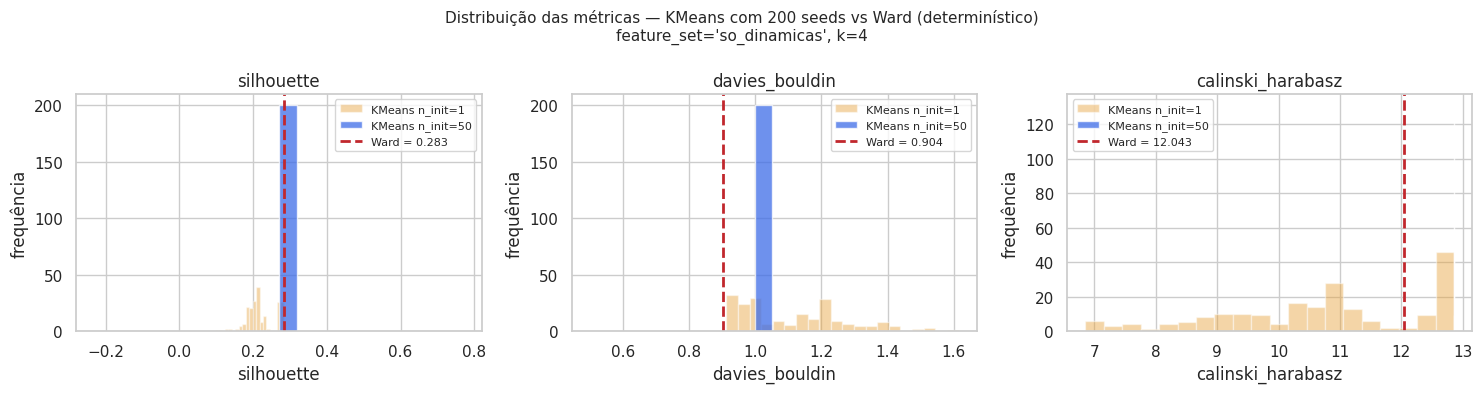

In [33]:
# Visualização: distribuição das três métricas sob n_init=50 e n_init=1, com Ward como linha vertical.

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, m in zip(axes, ["silhouette", "davies_bouldin", "calinski_harabasz"]):
    ax.hist(var_n1[m],  bins=20, alpha=0.45, label="KMeans n_init=1",  color="#e8a33d")
    ax.hist(var_n50[m], bins=20, alpha=0.75, label="KMeans n_init=50", color="#3d6ce8")
    ax.axvline(ward_metricas[m], color="#c1272d", linestyle="--", linewidth=2,
               label=f"Ward = {ward_metricas[m]:.3f}")
    ax.set_title(m)
    ax.set_xlabel(m)
    ax.set_ylabel("frequência")
    ax.legend(fontsize=8)

plt.suptitle(
    f"Distribuição das métricas — KMeans com {N_SEEDS} seeds vs Ward (determinístico)\n"
    f"feature_set='{vencedor['feature_set']}', k={K_FINAL}",
    fontsize=11
)
plt.tight_layout()
plt.show()


### 8.1 Síntese para a resposta ao orientador

Preencher os números abaixo depois de executar a seção. O conteúdo daqui é o que vai para o
e-mail de retorno ao orientador (e, depois, para a seção de metodologia da monografia).

- **Faixa de silhouette do KMeans em N=200 seeds (n_init=50):** `[min, max]` — `____`
- **Faixa correspondente sob n_init=1 (pior caso):** `____`
- **Valor do Ward:** `____` — está dentro/fora da faixa do KMeans `n_init=50`?
- **Partições estruturalmente distintas em 200 execuções (n_init=50):** `____` — modal em `____%`
  das execuções.
- **ARI médio entre pares de execuções (n_init=50):** `____`
- **A partição final reportada é a modal?** Sim / Não.

**Frase-resumo para o e-mail (adaptar com os números):** "Rodei o KMeans em 200 seeds
diferentes mantendo `n_init=50` (que é a configuração usada no notebook). Resultou em [N]
partição[ões] estruturalmente distinta[s], com a modal aparecendo em [X%] das execuções e
ARI médio entre pares de [Y]. A faixa de silhouette ficou entre [min] e [max], e a do Ward
(determinístico) é [valor]. Sob `n_init=1` (single shot, pior caso), a variabilidade aumenta
para [Z]. Concluo que o resultado do KMeans [não é / é parcialmente] um artefato de
inicialização, e que a diferença entre KMeans e Ward [está / não está] dentro da variância
esperada — o que [permite / não permite] que o critério de desempate seja a
interpretabilidade."

## 9. Inspeção qualitativa do(s) candidato(s) final(is)

Composição de clusters, perfil médio das features, e — se Ward estiver entre os finalistas —
o dendrograma, que tem valor narrativo independente do resultado da métrica.


In [34]:
def perfil_cluster(feats, k, algo, titulo=None):
    X = StandardScaler().fit_transform(df[feats])
    labels = fit_labels(X, k, algo)
    tmp = df.copy()
    tmp["cluster"] = labels

    print(f"\n=== {titulo or f'{feats} | k={k} | {algo}'} ===")
    for c in sorted(tmp["cluster"].unique()):
        circs = sorted(tmp.loc[tmp["cluster"] == c, "circuito"].tolist())
        print(f"Cluster {c} (n={len(circs)}): {circs}")

    print()
    print(tmp.groupby("cluster")[feats].mean().round(2))
    return tmp


In [37]:
# Lê o vencedor diretamente da Seção 7 (variável `vencedor`) — não editar manualmente.
# Se nenhum candidato foi aprovado pela rubrica, interrompe aqui em vez de seguir com um
# resultado arbitrário.
assert len(painel_aprovado) > 0, (
    "Nenhum candidato aprovado pela rubrica — revisar critérios antes de prosseguir para a "
    "inspeção qualitativa."
)

FEATS_FINAL = feature_sets[vencedor["feature_set"]]
K_FINAL = int(vencedor["k"])
ALGO_FINAL = vencedor["algo"]

print(f"Candidato final (lido automaticamente da Seção 7): "
      f"{vencedor['feature_set']}, k={K_FINAL}, {ALGO_FINAL}")

df_final = perfil_cluster(FEATS_FINAL, K_FINAL, ALGO_FINAL, titulo="Candidato final (vencedor da rubrica)")


Candidato final (lido automaticamente da Seção 7): so_dinamicas, k=4, kmeans

=== Candidato final (vencedor da rubrica) ===
Cluster 0 (n=11): ['Barcelona', 'Budapest', 'Imola', 'Jeddah', 'Le Castellet', 'Lusail', 'Silverstone', 'Sochi', 'Suzuka', 'São Paulo', 'Zandvoort']
Cluster 1 (n=8): ['Austin', 'Baku', 'Mexico City', 'Miami', 'Montréal', 'Sakhir', 'Shanghai', 'Yas Island']
Cluster 2 (n=5): ['Las Vegas', 'Melbourne', 'Monza', 'Spa-Francorchamps', 'Spielberg']
Cluster 3 (n=2): ['Monaco', 'Singapore']

         vel_media  vel_minima  zonas_freio  pico_desac  densidade_curvas
cluster                                                                  
0           227.64       96.18         9.09      -28.67              3.35
1           212.55       73.92         9.12      -33.45              3.39
2           242.44       82.35         7.60      -32.84              2.46
3           178.09       61.14        13.00      -30.95              5.18


In [36]:
# silhouette por circuito individual — identifica casos de fronteira
from sklearn.metrics import silhouette_samples

X_final = StandardScaler().fit_transform(df[FEATS_FINAL])
labels_final = fit_labels(X_final, K_FINAL, ALGO_FINAL)
sil_individual = silhouette_samples(X_final, labels_final)

sil_df = pd.DataFrame({
    "circuito": df["circuito"],
    "cluster": labels_final,
    "silhouette": sil_individual
}).sort_values("silhouette")

print("Circuitos com silhouette mais baixo (casos de fronteira candidatos):")
sil_df.head(8)


Circuitos com silhouette mais baixo (casos de fronteira candidatos):


,circuito,cluster,silhouette
20,Spa-Francorchamps,2,0.034599
3,Budapest,0,0.098066
22,Suzuka,0,0.113631
19,Sochi,0,0.114742
5,Jeddah,0,0.115654
6,Las Vegas,2,0.116505
23,São Paulo,0,0.164112
18,Singapore,3,0.171255


**O que procurar:** circuitos com silhouette individual baixo (< 0.10) são candidatos a
casos de fronteira — vale nomeá-los explicitamente na monografia como limitação reconhecida, em
vez de forçar uma narrativa de pertencimento claro a um grupo.


### 9.1 Investigação dos casos de fronteira: distância aos centróides

Silhouette baixo não diz, por si só, *para qual outro cluster* o circuito está mais próximo —
só que ele está mal-alocado em relação ao seu próprio grupo. Esta célula calcula a distância
euclidiana (no espaço padronizado) de cada caso de fronteira a todos os centróides, revelando
se ele está genuinamente "no meio do caminho" entre dois grupos específicos, ou se é um outlier
mais difuso sem afinidade clara com nenhum outro cluster.


In [38]:
N_FRONTEIRA = 4  # quantos casos de fronteira investigar (os de menor silhouette)

centroides = pd.DataFrame(X_final, columns=FEATS_FINAL)
centroides["cluster"] = labels_final
centroides = centroides.groupby("cluster")[FEATS_FINAL].mean()

casos_fronteira = sil_df.head(N_FRONTEIRA)

for _, row in casos_fronteira.iterrows():
    idx_circuito = df.index[df["circuito"] == row["circuito"]][0]
    ponto = X_final[idx_circuito]

    distancias = {
        c: np.linalg.norm(ponto - centroides.loc[c].to_numpy())
        for c in centroides.index
    }
    dist_ordenadas = sorted(distancias.items(), key=lambda x: x[1])

    print(f"\n{row['circuito']} (cluster atual: {row['cluster']}, silhouette: {row['silhouette']:.3f})")
    for cluster_id, dist in dist_ordenadas:
        marca = " <- alocado aqui" if cluster_id == row["cluster"] else ""
        print(f"  distância ao centróide do cluster {cluster_id}: {dist:.3f}{marca}")



Spa-Francorchamps (cluster atual: 2, silhouette: 0.035)
  distância ao centróide do cluster 2: 1.528 <- alocado aqui
  distância ao centróide do cluster 0: 2.035
  distância ao centróide do cluster 1: 2.046
  distância ao centróide do cluster 3: 5.139

Budapest (cluster atual: 0, silhouette: 0.098)
  distância ao centróide do cluster 0: 1.738 <- alocado aqui
  distância ao centróide do cluster 1: 2.436
  distância ao centróide do cluster 2: 3.507
  distância ao centróide do cluster 3: 3.813

Suzuka (cluster atual: 0, silhouette: 0.114)
  distância ao centróide do cluster 0: 1.311 <- alocado aqui
  distância ao centróide do cluster 2: 2.150
  distância ao centróide do cluster 1: 2.286
  distância ao centróide do cluster 3: 4.867

Sochi (cluster atual: 0, silhouette: 0.115)
  distância ao centróide do cluster 0: 1.662 <- alocado aqui
  distância ao centróide do cluster 1: 2.412
  distância ao centróide do cluster 2: 2.736
  distância ao centróide do cluster 3: 4.763


**Como interpretar:** se o circuito estiver alocado no cluster mais próximo (menor
distância) mesmo com silhouette baixo, o silhouette baixo reflete dispersão interna do cluster
(o grupo é heterogêneo), não um erro de alocação. Se o circuito estiver mais próximo do
centróide de *outro* cluster que não o seu, isso é evidência mais forte de fronteira genuína —
o ponto está, em distância pura, mais perto de um vizinho do que do próprio grupo, e o
algoritmo só não o moveu por causa de como a partição global se equilibra.


Correlação cofenética: 0.667


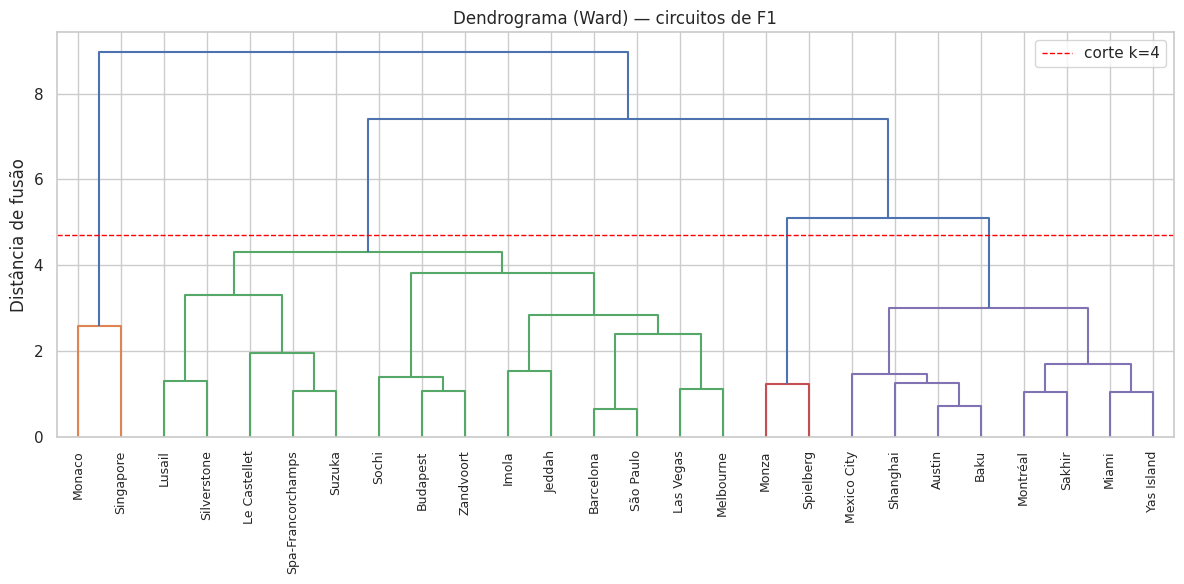

In [39]:
# dendrograma — gerar sempre que Ward estiver entre os finalistas avaliados, independente
# de ter vencido a rubrica, pelo valor narrativo para a banca
Z = linkage(X_final, method="ward")
coph, _ = cophenet(Z, pdist(X_final))
print(f"Correlação cofenética: {coph:.3f}")

plt.figure(figsize=(12, 6))
dendrogram(
    Z,
    labels=df["circuito"].values,
    leaf_rotation=90,
    leaf_font_size=9,
    color_threshold=Z[-(K_FINAL - 1), 2],
)
corte = (Z[-(K_FINAL - 1), 2] + Z[-K_FINAL, 2]) / 2
plt.axhline(corte, color="red", ls="--", lw=1, label=f"corte k={K_FINAL}")
plt.title("Dendrograma (Ward) — circuitos de F1")
plt.ylabel("Distância de fusão")
plt.legend()
plt.tight_layout()
plt.show()


## 10. Comparação com o resultado anterior

O resultado já fechado numa rodada anterior foi: k-means, k=4, conjunto `so_dinamicas`, com 88%
de concordância (por permutação) com Ward. Esta seção compara explicitamente o candidato vencedor
deste protocolo com aquele resultado.


In [40]:
RESULTADO_ANTERIOR = {
    "feature_set": "so_dinamicas",
    "k": 4,
    "algo": "kmeans",
}

X_anterior = StandardScaler().fit_transform(df[feature_sets[RESULTADO_ANTERIOR["feature_set"]]])
labels_anterior = fit_labels(X_anterior, RESULTADO_ANTERIOR["k"], RESULTADO_ANTERIOR["algo"])

ari_vs_anterior = adjusted_rand_score(labels_final, labels_anterior)
print(f"ARI entre candidato final e resultado anterior: {ari_vs_anterior:.3f}")

if ari_vs_anterior > 0.75:
    print("Convergência forte — o novo protocolo confirma o resultado anterior.")
elif ari_vs_anterior > 0.5:
    print("Convergência parcial — partições relacionadas mas não idênticas. Investigar diferenças.")
else:
    print("Divergência relevante — o novo protocolo aponta para um resultado diferente. Documentar por quê.")


ARI entre candidato final e resultado anterior: 1.000
Convergência forte — o novo protocolo confirma o resultado anterior.


**Se houver divergência:** isso não é necessariamente um problema — é informação. Vale
investigar quais circuitos migraram de cluster e se a explicação física faz mais sentido na
partição nova ou na antiga, documentando a decisão final com a razão explícita.


## 11. Síntese e exportação

Preencher após executar o notebook com os resultados reais:

- Qual combinação `(feature_set, k, algoritmo)` venceu a rubrica, e por quê
- Quantos candidatos foram aprovados nos filtros de estabilidade/concordância
- Casos de fronteira identificados (circuitos com silhouette individual baixo)
- Resultado da comparação com a rodada anterior (confirmação ou divergência)
- Decisão final sobre `pico_desac` no vetor de clustering, à luz do desempenho de
  `so_dinamicas_sem_pico` no grid


In [41]:
# exporta o resultado final para uso na Etapa 2 (Subgroup Discovery)
df_export = df[["circuito"]].copy()
df_export["cluster_final"] = labels_final

# mantém os clusters de algoritmos alternativos testados, para auditoria/reprodutibilidade
df_export["cluster_kmeans_so_dinamicas_k4"] = labels_anterior

df_export.to_csv("../data/processed/clusters_circuitos.csv", index=False)
print(f"Exportado: clusters_circuitos.csv ({len(df_export)} linhas)")
df_export.head()


Exportado: clusters_circuitos.csv (26 linhas)


,circuito,cluster_final,cluster_kmeans_so_dinamicas_k4
0,Austin,1,1
1,Baku,1,1
2,Barcelona,0,0
3,Budapest,0,0
4,Imola,0,0
